# 01 · Gerçek veri ve MM sistemlerinin hazırlanması
*Makale: Şekil 2 "Structure Preparation and Equilibration (MM)".*

1. Yayımlanmış benchmark girdilerini indiriyoruz: solvatize edilmiş bCD–siklopentanol kompleksi
   (q4md-CD + GAFF kuvvet alanı, TIP3P su, 1500 su molekülü).
2. **Kompleks bacağını** dosyadan olduğu gibi alıyoruz.
3. **Çözücü bacağı** için aynı kutudan konakçıyı silip misafiri saf suda bırakıyoruz.
4. Her iki sistemi NPT (298 K, 1 bar) koşullarında dengeliyoruz.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
from qfe import config, store
from qfe.plotting import C, LEG, LEG_TR
import numpy as np, matplotlib.pyplot as plt
# Ön ayar: "test" (hızlı kontrol), "demo" (ekibe gösterim), "standart" (daha güvenilir)
config.set_preset(os.environ.get("QFE_PRESET", "demo"))
print("Aktif ön ayar:", config.preset_name())

Aktif ön ayar: test


In [2]:
from qfe import mmsys
with store.timed("01_indirme"):
    files = mmsys.download_inputs()

  prmtop     -> bcd-3-s.prmtop (780 kB)
  rst7       -> bcd-3-s.rst7 (333 kB)
  guest_sdf  -> guest-3.sdf (2 kB)
  host_pdb   -> host-bcd.pdb (15 kB)
  deney_tablosu -> README_cdset2.md (4 kB)
[süre] 01_indirme: 0.0 s


In [3]:
# Deneysel veri (benchmark README'sinden; Rekharsky et al. 1997)
dG, sem = config.exp_dG_kj()
print(f"Deneysel ΔG_bağlanma (bCD + siklopentanol, 298 K): {dG:.2f} ± {sem:.2f} kJ/mol "
      f"({config.SYSTEM['exp_dG_kcal']} kcal/mol)")
store.save_json("results.json", {"exp_dG_kJ": dG, "exp_dG_err_kJ": sem})

Deneysel ΔG_bağlanma (bCD + siklopentanol, 298 K): -12.76 ± 0.04 kJ/mol (-3.05 kcal/mol)


PosixPath('/home/claude/qb/results/test/results.json')

In [4]:
legs = mmsys.build_legs(files)
for leg, (_, _, summ) in legs.items():
    print(f"{leg:8s}: {summ['atoms']} atom, rezidüler={summ['residues']}, net yük={summ['net_charge']}")

complex : 4669 atom, rezidüler={'MGO': 7, 'MOL': 1, 'Na+': 3, 'Cl-': 3, 'WAT': 1500}, net yük=-0.0
solvent : 4522 atom, rezidüler={'MOL': 1, 'Na+': 3, 'Cl-': 3, 'WAT': 1500}, net yük=-0.0


### Moleküle bakış (isteğe bağlı)
`py3Dmol` kuruluysa kompleksin 3B görüntüsü aşağıda çıkar (su molekülleri gizli).

In [5]:
try:
    import py3Dmol, parmed as pmd
    s = pmd.load_file(str(config.DATA / "complex.prmtop"), xyz=str(config.DATA / "complex.rst7"))
    sub = s[":MGO,MOL"]
    pdb = config.DATA / "complex_dry.pdb"; sub.save(str(pdb), overwrite=True)
    v = py3Dmol.view(width=520, height=380)
    v.addModel(open(pdb).read(), "pdb")
    v.setStyle({"resn": "MGO"}, {"stick": {"radius": 0.12, "color": "lightgray"}})
    v.setStyle({"resn": "MOL"}, {"stick": {"radius": 0.22, "colorscheme": "orangeCarbon"}, "sphere": {"scale": 0.25}})
    v.zoomTo(); v.show()
except ImportError:
    print("py3Dmol yok (pip install py3Dmol) — görselleştirme atlandı.")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### NPT dengeleme

OpenMM platformu: CPU  (mevcut: ['Reference', 'CPU'])


complex: 20 ps NPT, 54.9 s  (~31 ns/gün)
[süre] 01_dengeleme_complex: 71.1 s
OpenMM platformu: CPU  (mevcut: ['Reference', 'CPU'])


solvent: 20 ps NPT, 53.3 s  (~32 ns/gün)
[süre] 01_dengeleme_solvent: 66.1 s


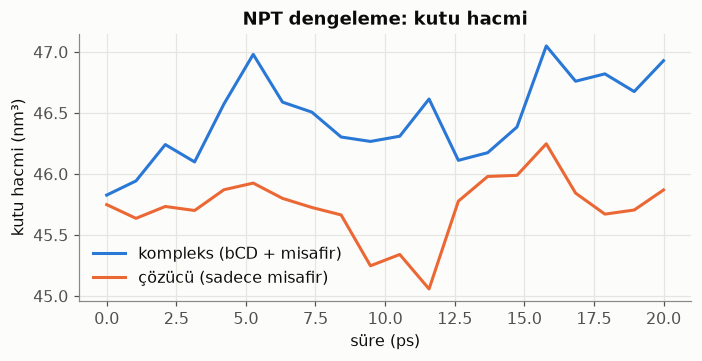

In [6]:
eq = {}
for leg in ["complex", "solvent"]:
    with store.timed(f"01_dengeleme_{leg}") as rec:
        eq[leg] = mmsys.equilibrate(leg)
        rec["ns_per_day"] = eq[leg]["ns_per_day"]
store.save_json("results.json", {"md_ns_per_day": eq["complex"]["ns_per_day"]})

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for leg in eq:
    v = np.array(eq[leg]["volumes_nm3"])
    ax.plot(np.linspace(0, config.P()["equil_npt_ps"], len(v)), v, color=LEG[leg], label=LEG_TR[leg])
ax.set_xlabel("süre (ps)"); ax.set_ylabel("kutu hacmi (nm³)")
ax.set_title("NPT dengeleme: kutu hacmi")
ax.legend(); plt.tight_layout(); plt.show()

**Ne görmeliyiz?** Çözücü bacağında konakçı silindiği için boş bir oyuk kalıyor. Barostat kutuyu
küçülterek bu oyuğu suyla dolduruyor, bu yüzden hacim düşüp sabitlenmeli. Hacim hâlâ düşüyorsa
`equil_npt_ps` değerini artırın.

**Maliyet notu:** Hücrenin çıktısındaki *ns/gün* değeri MD hızınız. 07. notebook bunu kullanarak
gerçek bir protein sistemi için gereken GPU süresini tahmin edecek.